# Predicting Iris Flower Species with Machine Learning
### DATASCI 530 · Assignment 5 · Whitney Barr


**Key findings**
- The data contain **150 flowers, 4 features, and 3 equally sized classes** (33.3% each).
- Using cross-validation, the **SVM (96.7% accuracy), random forest (96.7%), and tuned neural network (97.3%)** perform almost identically. The ridge classifier is less accurate at 82%.
- **The support vector machine method is recommended.** The neural network is a close second.
- **New insight** - *Iris-setosa* is completely separable from the other two species using petal measurements, whereas *Iris-versicolor* and *Iris-virginica* overlap. This is where classification is hardest.


## 1. Setup

I use `sklearn` for all four methods, so I fit and evaluate them with the same syntax.

In [1]:
# Import the package for the University of California Irvine API
from ucimlrepo import fetch_ucirepo

# Import SK-Learn library for machine learning functions
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_validate
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import RidgeClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Import standard data analysis packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Dataset Description

The Iris dataset comes from the UC Irvine Machine Learning Repository (id = 53). 

- `X` is the feature matrix: four flower measurements in centimeters.
- `y` is the label I want to predict: the flower species ("class").

The photo below shows the three species. The four features are the length and width of the sepals (the outer leaves of the flower) and of the petals.

![Photos of the three iris species: Iris Versicolor, Iris Setosa and Iris Virginica, with a sepal and a petal labeled](iris_species.png)

In [2]:
# Fetch data from the UC Irvine Machine Learning Repository API
iris = fetch_ucirepo(id=53)

# Extract features (X) and label (y)
X = iris.data.features
y = iris.data.targets["class"]

### a) Size of the dataset

Number of rows (flowers) and number of features:

In [3]:
print("Number of rows:", len(X))
print("Number of features:", X.shape[1])
print("Feature names:", list(X.columns))

Number of rows: 150
Number of features: 4
Feature names: ['sepal length', 'sepal width', 'petal length', 'petal width']


### b) Proportion of observations in each class

In [4]:
# Compute frequency table for the label
table_y = pd.crosstab(y, "proportion") / len(y)

table_y_pretty = table_y.rename_axis(index = "Species", columns = None).reset_index()

table_y_pretty.style.format({"proportion": "{:.1%}"}).hide(axis = "index").set_caption("Proportion of observations by class")

Species,proportion
Iris-setosa,33.3%
Iris-versicolor,33.3%
Iris-virginica,33.3%


The classes are balanced (50 each), so accuracy is a fair metric.

### c) Quality checks

Before modeling, I check for missing values in the features and the label, and I compute descriptive statistics for the features.

In [5]:
# Count missing values in each feature
print("Missing values per feature:")
print(X.isna().sum())
print("Missing values in the label:", y.isna().sum())

Missing values per feature:
sepal length    0
sepal width     0
petal length    0
petal width     0
dtype: int64
Missing values in the label: 0


In [6]:
# Descriptive statistics of the features
X.describe().style.format("{:.2f}").set_caption("Descriptive statistics of the features (cm)")

,sepal length,sepal width,petal length,petal width
count,150.00,150.00,150.00,150.00
mean,5.84,3.05,3.76,1.20
std,0.83,0.43,1.76,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


There are **no missing values**, so no rows were dropped or imputed.

## 3. Comparison of Machine Learning Methods

### 3.1 Methodology

- **Methods** - I compare a support vector machine (SVM), a random forest, a neural network, and a **ridge classifier**, which is my extra method (a linear model). I use `sklearn`'s `MLPClassifier` for the neural network, because I could not get Keras to run on my computer and this lets me cross-validate it the same way as the other methods.
- **Cross-validation** - I evaluate every method with 5-fold cross-validation (`cv=5`).
- **Scaling** - The SVM, neural network, and ridge classifier work better when the features are on a similar scale, so I put them in a `Pipeline` with a `StandardScaler`.
- **Metrics** - I report accuracy (the share of flowers classified correctly) plus precision, recall, and F1, averaged across the three species.
- **Tuning** - All methods use their default settings except the **neural network**, which is my one tuned method (Section 3.3).

### 3.2 Methods with default settings

**Approach** I fit the SVM, random forest, and ridge classifier with their default settings.

In [7]:
# Metrics to compute in cross-validation
metrics = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]

# SVM with default parameters (scaled features)
pipe_svm = Pipeline([("scaler", StandardScaler()),
                     ("svm", SVC())])

# Ridge classifier with default parameters (scaled features)
pipe_ridge = Pipeline([("scaler", StandardScaler()),
                       ("ridge", RidgeClassifier())])

# Random forest with default parameters
rf = RandomForestClassifier(random_state = 0)

res_svm   = cross_validate(pipe_svm,   X, y, scoring = metrics, cv = 5)
res_ridge = cross_validate(pipe_ridge, X, y, scoring = metrics, cv = 5)
res_rf    = cross_validate(rf,         X, y, scoring = metrics, cv = 5)

### 3.3 Tuning the neural network

**Approach**
- I try four network sizes (the **grid of tuning parameters**) and keep the one that scores best in cross-validation.
- The four sizes are one hidden layer with 10, 50, or 100 units, and two hidden layers with 10 units each.

In [8]:
# Neural network pipeline (scaled features)
pipe_nn = Pipeline([("scaler", StandardScaler()),
                    ("nn", MLPClassifier(random_state = 0))])

# Grid of tuning parameters: use the step name, two underscores, and the parameter name
param_grid = {"nn__hidden_layer_sizes": [(10,), (50,), (100,), (10, 10)],
              "nn__max_iter":           [1000]}

# Configure and run the grid search with 5-fold cross-validation
grid = GridSearchCV(pipe_nn, param_grid, cv = 5,
                    return_train_score = True,
                    n_jobs = -1)

grid.fit(X, y)

print("Best estimator:\n{}".format(grid.best_estimator_))

Best estimator:
Pipeline(steps=[('scaler', StandardScaler()),
                ('nn',
                 MLPClassifier(hidden_layer_sizes=(50,), max_iter=1000,
                               random_state=0))])


The best neural network is printed above. Next, I measure how well it does using the same 5-fold cross-validation as the other methods.

In [9]:
res_nn = cross_validate(grid.best_estimator_, X, y, scoring = metrics, cv = 5)

### 3.4 Results

In [10]:
# Average each metric across the 5 folds
results_table = pd.DataFrame({"SVM (default)":              pd.DataFrame(res_svm).mean(),
                              "Random forest (default)":    pd.DataFrame(res_rf).mean(),
                              "Neural network (tuned)":     pd.DataFrame(res_nn).mean(),
                              "Ridge classifier (default)": pd.DataFrame(res_ridge).mean()})

# Keep only the performance metrics and give them readable names
results_table = results_table.loc[["test_accuracy", "test_precision_macro", "test_recall_macro", "test_f1_macro"]]
results_table = results_table.rename(index = {"test_accuracy":        "Accuracy",
                                              "test_precision_macro": "Precision",
                                              "test_recall_macro":    "Recall",
                                              "test_f1_macro":        "F1"})

results_table.style.format("{:.3f}").set_caption("5-fold cross-validated performance (average across folds)")

,SVM (default),Random forest (default),Neural network (tuned),Ridge classifier (default)
Accuracy,0.967,0.967,0.973,0.820
Precision,0.968,0.971,0.976,0.829
Recall,0.967,0.967,0.973,0.820
F1,0.967,0.966,0.973,0.818


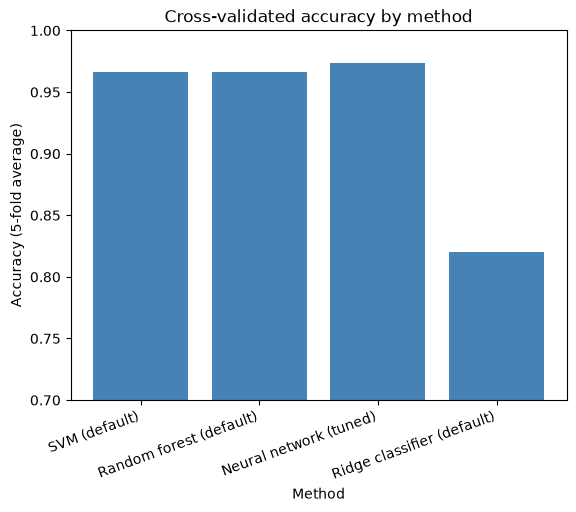

In [11]:
# Bar chart of cross-validated accuracy for each method
plt.bar(results_table.columns, results_table.loc["Accuracy"], color = "steelblue")
plt.ylim(0.7, 1.0)
plt.title("Cross-validated accuracy by method")
plt.xlabel("Method")
plt.ylabel("Accuracy (5-fold average)")
plt.xticks(rotation = 20, ha = "right")
plt.show()

**Interpretation**

- The **SVM (96.7%), random forest (96.7%), and neural network (97.3%)** are basically tied. The 0.7 point gap between them is **one flower** out of 150.
- The **ridge classifier is clearly worse at 82.0%**.
- Precision, recall, and F1 rank the methods in the same order as accuracy.

**Caveat** I picked the neural network's settings using the same cross-validation I report, so its score is a little optimistic. The other methods were not tuned, so this does not affect them.

**Recommendation - the support vector machine.** It scores about as well as the best methods, needs no tuning, and is simple and fast. The neural network is 0.7 points higher, but that is one flower, which does not justify the extra tuning.

### 3.5 Test on unseen data (SVM)

As a final check, I train the recommended SVM on 75% of the flowers and test it on the other 25%. The confusion matrix shows the share of test flowers in each cell, so the diagonal is the correct predictions.

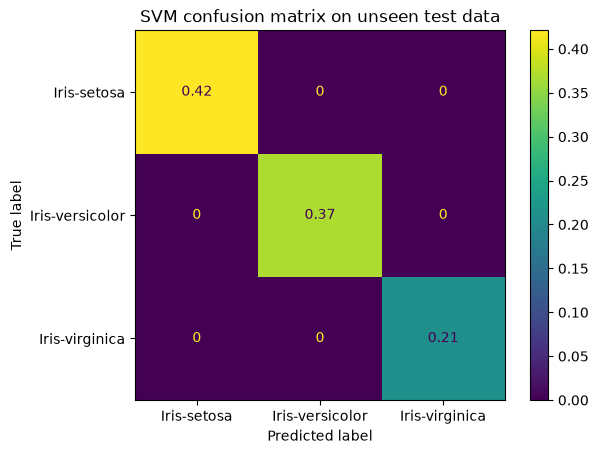

In [12]:
# Split into training and test data
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                   random_state = 104,
                                   test_size = 0.25,
                                   shuffle = True)

# Fit the pipeline (the scaler is learned from the training data only)
pipe_svm.fit(X_train, y_train)

# Out-of-sample predictions
predictions = pipe_svm.predict(X_test)

# Compute confusion matrix
cm = confusion_matrix(y_test, predictions, labels = pipe_svm.classes_) / len(y_test)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix = cm,
                              display_labels = pipe_svm.classes_)
disp.plot()
plt.title("SVM confusion matrix on unseen test data")
plt.show()

In [13]:
print("Test set size:", len(y_test))
print("Test accuracy:", round(pipe_svm.score(X_test, y_test), 3))

Test set size: 38
Test accuracy: 1.0


The SVM classified all 38 test flowers correctly. That agrees with the cross-validation results, but a test set this small cannot rank the methods, so my recommendation rests on cross-validation.

## 4. New Insight - What Separates the Species?

Why are some species easy to classify and others harder?

**Approach**
- I compute the average of each measurement by species.
- I plot the two petal measurements for all 150 flowers, with one color per species.

In [14]:
# Combine features and label, then compute the mean of each feature by species
iris_all = pd.concat([X, y], axis = 1)
means_table = iris_all.groupby("class").mean().round(2)

means_table.style.format("{:.2f}").set_caption("Average measurement by species (cm)")

,sepal length,sepal width,petal length,petal width
class,,,,
Iris-setosa,5.01,3.42,1.46,0.24
Iris-versicolor,5.94,2.77,4.26,1.33
Iris-virginica,6.59,2.97,5.55,2.03


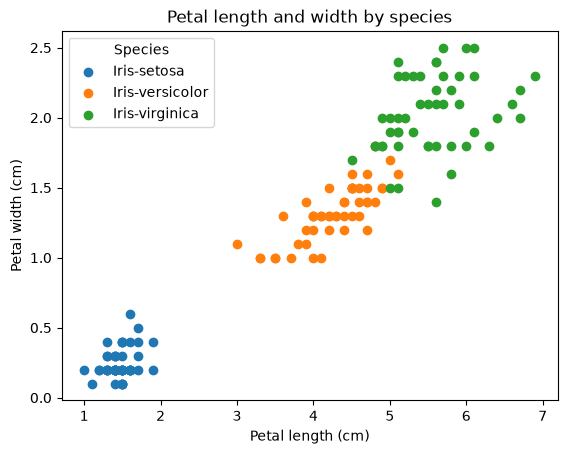

In [15]:
# Scatter plot of the petal measurements, one color per species
list_classes = ["Iris-setosa", "Iris-versicolor", "Iris-virginica"]

for species in list_classes:
    plt.scatter(x = X.loc[y == species, "petal length"],
                y = X.loc[y == species, "petal width"])

plt.legend(labels = list_classes, title = "Species")
plt.title("Petal length and width by species")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.show()

## 5. What do we learn from it?

**Setosa is easy to identify** Its petals are much smaller than the other species (average length 1.46 cm vs. 4.26 cm and 5.55 cm). In the scatter plot, Setosa forms its own cluster.

**Versicolor and virginica overlap** Their petal sizes are closer, and the two groups touch in the middle of the plot. Flowers near that boundary are the hardest to classify.

This probably explains why the SVM, random forest, and neural network all reach about 97%: they separate setosa easily and miss the same few borderline flowers. This is my reading of the plot, not something I tested. The ridge classifier draws a straight boundary, so it has more trouble in the overlap, which fits its lower accuracy.

**Limitations** The results could change with a different random split, and I tuned only one method, over a small grid.